1. Préparation des données

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, silhouette_score, classification_report, confusion_matrix
from scipy.stats import ks_2samp

# Chemin des données
DATA_DIR = Path(r"C:\document ons\mlops\data\raw\hai\hai-23.05")

# Chargement Train et Test
df_train = pd.concat(
    [pd.read_csv(DATA_DIR / f"hai-train{i}.csv") for i in range(1, 5)],
    ignore_index=True
)

df_test = pd.concat(
    [pd.read_csv(DATA_DIR / f"hai-test{i}.csv") for i in range(1, 3)],
    ignore_index=True
)

# Chargement des labels
df_labels = pd.concat(
    [pd.read_csv(DATA_DIR / f"label-test{i}.csv") for i in range(1, 3)],
    ignore_index=True
)

# Préparation des données
label_col = next(c for c in df_labels.columns if "label" in c.lower())
df_test_labeled = df_test.copy()
df_test_labeled["__label__"] = df_labels[label_col].values

sensor_cols = df_train.select_dtypes(include=np.number).columns.tolist()

print("Train :", df_train.shape)
print("Test :", df_test.shape)
print("Labels :", df_labels.shape)
print("Capteurs :", len(sensor_cols))

Train : (896400, 87)
Test : (284400, 87)
Labels : (284400, 2)
Capteurs : 86


2. Matrice de corrélation

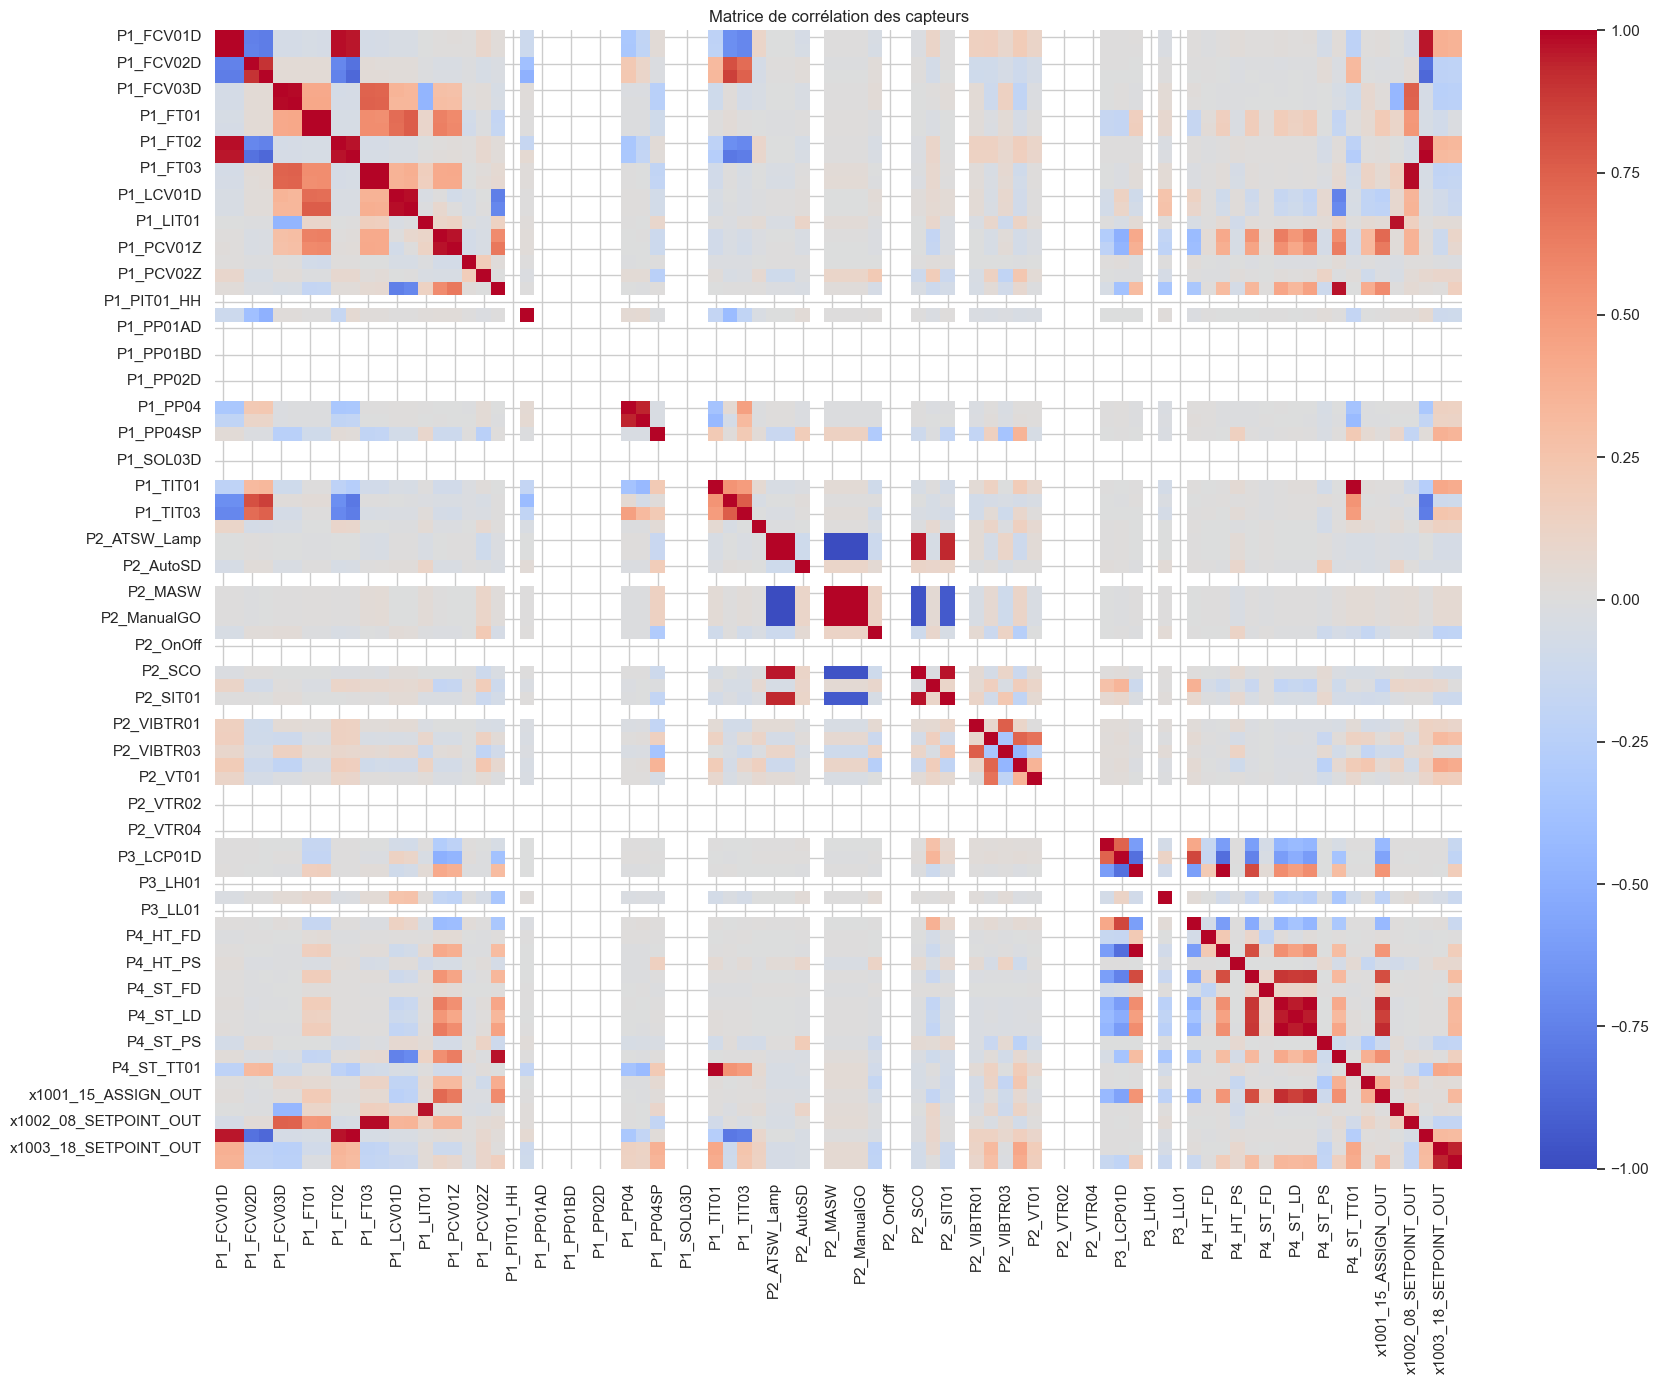

Nombre de paires fortement corrélées : 40


,Feature_1,Feature_2,Correlation
0,P2_AutoGO,P2_MASW,-1.000000
1,P2_AutoGO,P2_MASW_Lamp,-1.000000
2,P2_AutoGO,P2_ManualGO,-1.000000
3,P2_MASW,P2_MASW_Lamp,1.000000
4,P2_ATSW_Lamp,P2_ManualGO,-1.000000
5,P2_ATSW_Lamp,P2_MASW_Lamp,-1.000000
6,P2_ATSW_Lamp,P2_MASW,-1.000000
7,P2_ATSW_Lamp,P2_AutoGO,1.000000
8,P2_MASW_Lamp,P2_ManualGO,1.000000
9,P2_MASW,P2_ManualGO,1.000000


In [13]:
sample = df_train[sensor_cols].sample(
    n=min(30000, len(df_train)),
    random_state=42
)

corr_matrix = sample.corr()

plt.figure(figsize=(18, 14))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Matrice de corrélation des capteurs")
plt.tight_layout()
plt.show()

# Extraction des paires de capteurs
corr_pairs = (
    corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )
    .stack()
    .rename("Correlation")
    .reset_index()
)

corr_pairs.columns = ["Feature_1", "Feature_2", "Correlation"]

# Sélection des corrélations fortes
strong_corr = (
    corr_pairs[corr_pairs["Correlation"].abs() >= 0.95]
    .sort_values("Correlation", key=abs, ascending=False)
    .reset_index(drop=True)
)
print("Nombre de paires fortement corrélées :", len(strong_corr))
display(strong_corr.head(20))

L'analyse révèle 40 paires de variables fortement corrélées. Cette redondance indique que certains capteurs fournissent des informations similaires, ce qui doit être pris en compte lors de la sélection des variables.

3. Relations entre capteurs

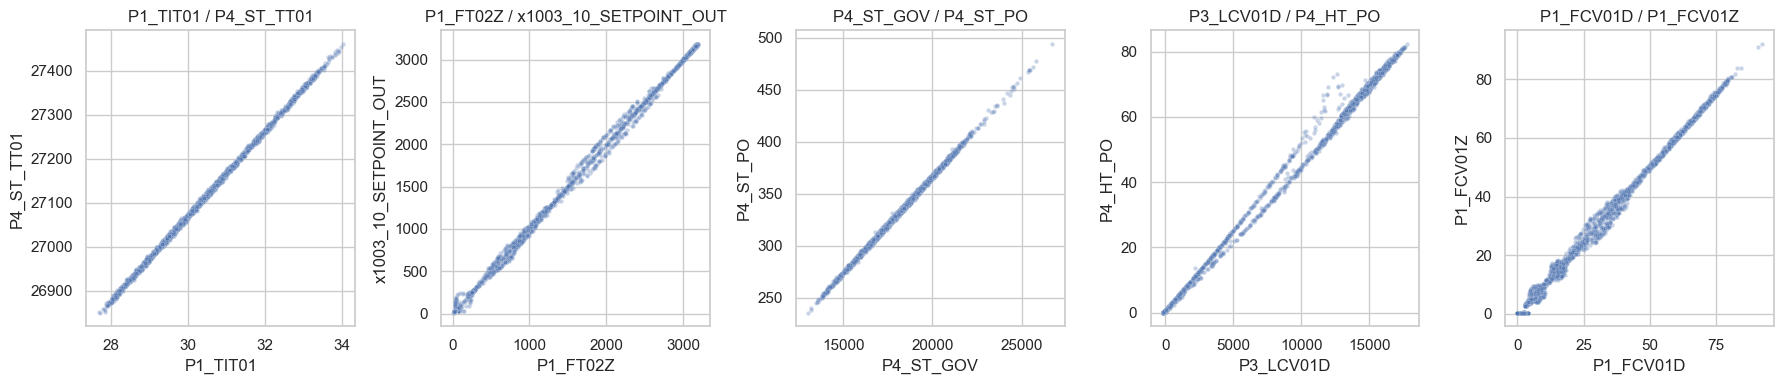

In [15]:
top_pairs = strong_corr[
    strong_corr["Feature_1"].map(lambda x: sample[x].nunique() > 2)
    & strong_corr["Feature_2"].map(lambda x: sample[x].nunique() > 2)
].head(5)

fig, axes = plt.subplots(1, len(top_pairs), figsize=(18, 4))
axes = np.atleast_1d(axes)

for ax, (_, row) in zip(axes, top_pairs.iterrows()):
    sns.scatterplot(
        data=sample.sample(min(3000, len(sample)), random_state=42),
        x=row["Feature_1"],
        y=row["Feature_2"],
        alpha=0.3,
        s=10,
        ax=ax
    )
    ax.set_title(f'{row["Feature_1"]} / {row["Feature_2"]}')

plt.tight_layout()
plt.show()

4. Analyse en composantes principales (PCA)

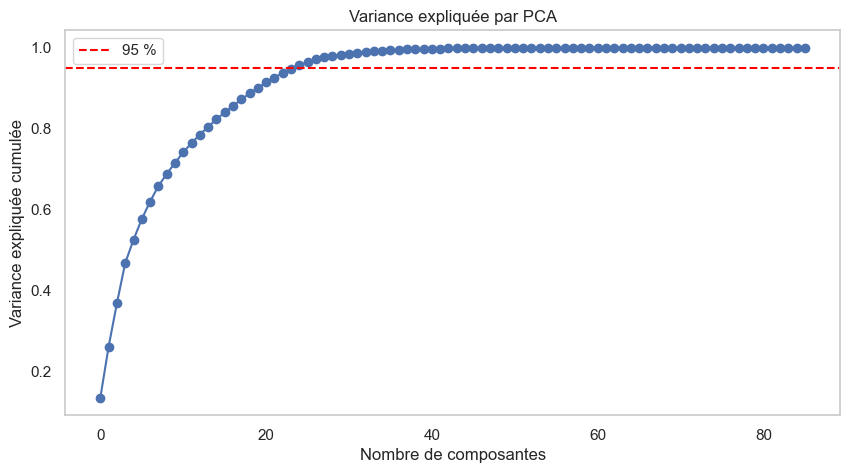

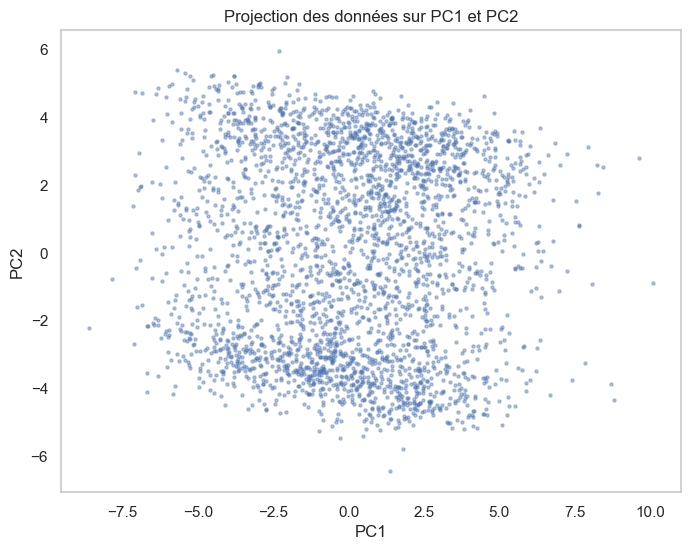

Variance expliquée par PC1 et PC2 : 26.2 %
Composantes nécessaires pour 95 % : 25


In [ ]:
pca_sample = df_train[sensor_cols].sample(
    min(30000, len(df_train)), random_state=42
)

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(pca_sample)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Application de PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Variance expliquée cumulée 
cum_var = np.cumsum(pca.explained_variance_ratio_)

plt.figure(figsize=(10, 5))
plt.plot(cum_var, marker="o")
plt.axhline(0.95, color="red", linestyle="--", label="95 %")
plt.xlabel("Nombre de composantes")
plt.ylabel("Variance expliquée cumulée")
plt.title("Variance expliquée par PCA")
plt.legend()
plt.grid()
plt.show()

# Projection sur les deux premières composantes
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:3000, 0], X_pca[:3000, 1], s=5, alpha=0.4)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Projection des données sur PC1 et PC2")
plt.grid()
plt.show()

print("Variance expliquée par PC1 et PC2 :",
      round(cum_var[1] * 100, 2), "%")
print("Composantes nécessaires pour 95 % :",
      np.argmax(cum_var >= 0.95) + 1)

Les deux premières composantes expliquent seulement 26,2 % de la variance. Il faut 25 composantes pour atteindre 95 %, ce qui montre la complexité multivariée des données.

5. Détection des outliers avec Isolation Forest

Nombre d'outliers : 300
Pourcentage d'outliers : 1.0 %


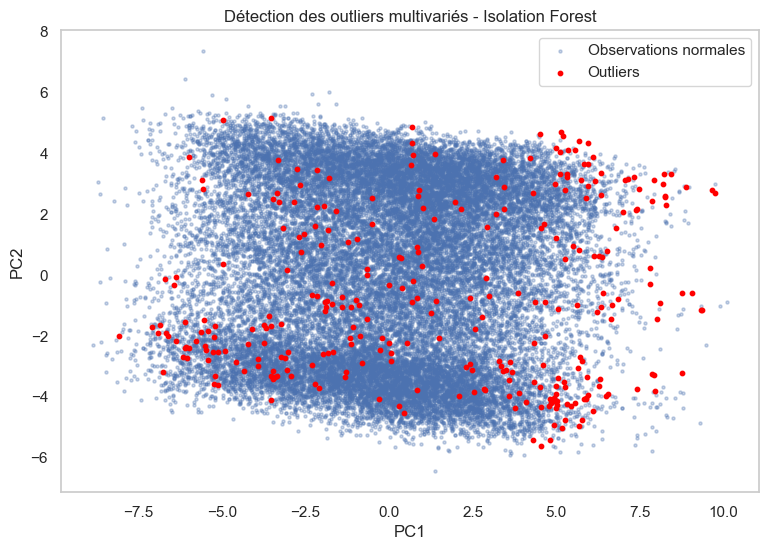

In [19]:
# Application d'Isolation Forest
iso = IsolationForest(
    contamination=0.01,
    random_state=42
)

outlier_labels = iso.fit_predict(X_scaled)

# Résultats
n_outliers = (outlier_labels == -1).sum()
print("Nombre d'outliers :", n_outliers)
print("Pourcentage d'outliers :", round(n_outliers / len(X_scaled) * 100, 2), "%")

# Visualisation sur les deux premières composantes PCA
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[outlier_labels == 1, 0],
    X_pca[outlier_labels == 1, 1],
    s=5,
    alpha=0.3,
    label="Observations normales"
)

plt.scatter(
    X_pca[outlier_labels == -1, 0],
    X_pca[outlier_labels == -1, 1],
    s=10,
    color="red",
    label="Outliers"
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Détection des outliers multivariés - Isolation Forest")
plt.legend()
plt.grid()
plt.show()

Isolation Forest identifie 1 % d'observations aberrantes. Toutefois, cette proportion est imposée par le paramètre `contamination=0.01` et ne représente pas nécessairement le taux réel d'anomalies ou d'attaques.

6. Analyse de redondance

In [21]:
# Construction d'une matrice de corrélation absolue
corr_abs = corr_matrix.abs()

# Identification des groupes de capteurs corrélés
redundancy_groups = corr_abs.where(
    np.triu(np.ones(corr_abs.shape), k=1).astype(bool)
).stack()

redundancy_groups = redundancy_groups[
    redundancy_groups >= 0.95
]

# Affichage des groupes de variables concernées
redundant_features = sorted(set(
    redundancy_groups.index.get_level_values(0)
).union(
    redundancy_groups.index.get_level_values(1)
))

print("Nombre de capteurs redondants :", len(redundant_features))
print("\nCapteurs concernés :")
print(redundant_features)

Nombre de capteurs redondants : 34

Capteurs concernés :
['P1_FCV01D', 'P1_FCV01Z', 'P1_FCV03D', 'P1_FCV03Z', 'P1_FT01', 'P1_FT01Z', 'P1_FT02', 'P1_FT02Z', 'P1_FT03', 'P1_FT03Z', 'P1_LCV01D', 'P1_LCV01Z', 'P1_LIT01', 'P1_PCV01D', 'P1_PCV01Z', 'P1_PIT01', 'P1_TIT01', 'P2_ATSW_Lamp', 'P2_AutoGO', 'P2_MASW', 'P2_MASW_Lamp', 'P2_ManualGO', 'P2_SCO', 'P2_SIT01', 'P3_LCV01D', 'P4_HT_PO', 'P4_ST_GOV', 'P4_ST_LD', 'P4_ST_PO', 'P4_ST_PT01', 'P4_ST_TT01', 'x1002_07_SETPOINT_OUT', 'x1002_08_SETPOINT_OUT', 'x1003_10_SETPOINT_OUT']


7. Évaluation individuelle des capteurs avec ROC-AUC

,Feature,AUC,AUC_oriented,Direction,N
0,P1_TIT01,0.657454,0.657454,Valeurs élevées associées aux attaques,284400
1,P4_ST_TT01,0.657176,0.657176,Valeurs élevées associées aux attaques,284400
2,P1_PIT02,0.375363,0.624637,Valeurs faibles associées aux attaques,284400
3,x1003_18_SETPOINT_OUT,0.601060,0.601060,Valeurs élevées associées aux attaques,284400
4,x1003_24_SUM_OUT,0.598703,0.598703,Valeurs élevées associées aux attaques,284400
5,P4_ST_PS,0.592411,0.592411,Valeurs élevées associées aux attaques,284400
6,P3_LIT01,0.579578,0.579578,Valeurs élevées associées aux attaques,284400
7,P1_PP04D,0.420443,0.579557,Valeurs faibles associées aux attaques,284400
8,P1_PCV01Z,0.576017,0.576017,Valeurs élevées associées aux attaques,284400
9,P1_TIT02,0.575626,0.575626,Valeurs élevées associées aux attaques,284400


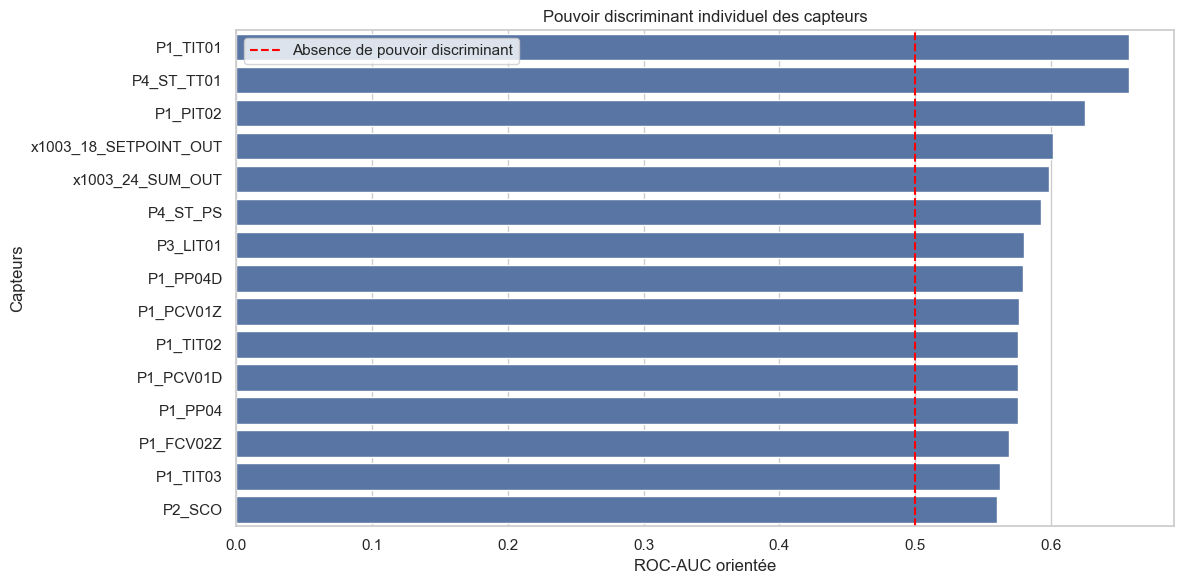

In [26]:

# 1. Préparation des labels
y = pd.to_numeric(
    df_test_labeled["__label__"],
    errors="coerce"
)

# 2. Calcul du pouvoir discriminant individuel
feature_scores = []

for col in sensor_cols:

    data = pd.DataFrame({
        "feature": pd.to_numeric(
            df_test_labeled[col], errors="coerce"
        ),
        "label": y
    })

    data = data.replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    if data["label"].nunique() != 2:
        continue

    if data["feature"].nunique() <= 1:
        continue

    auc = roc_auc_score(
        data["label"], data["feature"]
    )

    feature_scores.append({
        "Feature": col,
        "AUC": auc,
        "AUC_oriented": max(auc, 1 - auc),
        "Direction": (
            "Valeurs élevées associées aux attaques"
            if auc >= 0.5
            else "Valeurs faibles associées aux attaques"
        ),
        "N": len(data)
    })

# 3. Classement
feature_scores = pd.DataFrame(feature_scores)

feature_scores = feature_scores.sort_values(
    "AUC_oriented", ascending=False
).reset_index(drop=True)

display(feature_scores.head(15))

# 4. Visualisation
plt.figure(figsize=(12, 6))

sns.barplot(
    data=feature_scores.head(15),
    x="AUC_oriented",
    y="Feature"
)

plt.axvline(
    0.5, color="red", linestyle="--",
    label="Absence de pouvoir discriminant"
)

plt.title("Pouvoir discriminant individuel des capteurs")
plt.xlabel("ROC-AUC orientée")
plt.ylabel("Capteurs")
plt.legend()
plt.tight_layout()
plt.show()


Les résultats montrent qu'aucun capteur seul ne permet de détecter efficacement les attaques. La meilleure AUC est obtenue par `P1_TIT01` (0,657). Cela confirme l'intérêt d'une approche multivariée combinant plusieurs capteurs.

8. Comparaison Normal vs Attack

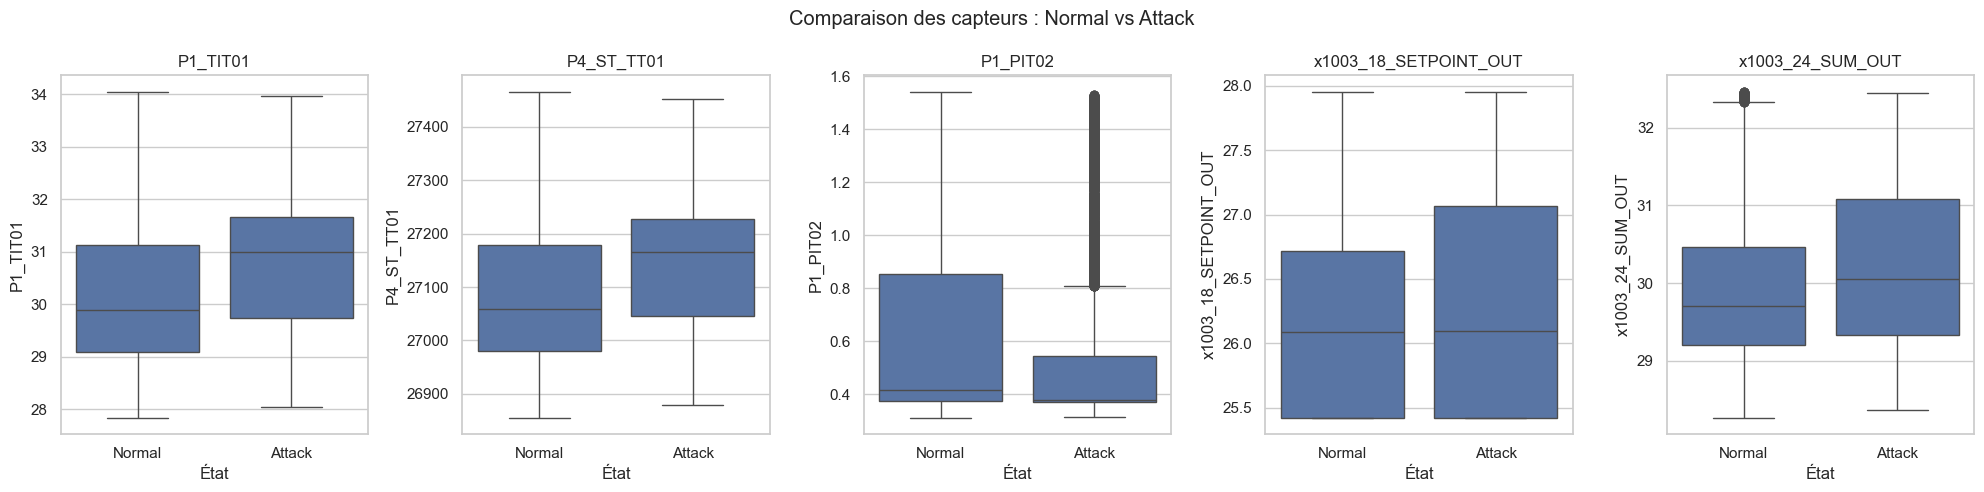

In [23]:
# Sélection des 5 meilleurs capteurs
top_features = feature_scores.head(5)["Feature"].tolist()

# Préparation des données
plot_data = df_test_labeled[top_features + ["__label__"]].copy()
plot_data["Etat"] = plot_data["__label__"].map({
    0: "Normal",
    1: "Attack"
})

# Visualisation
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

for ax, col in zip(axes, top_features):
    sns.boxplot(
        data=plot_data,
        x="Etat",
        y=col,
        ax=ax
    )
    ax.set_title(col)
    ax.set_xlabel("État")

plt.suptitle("Comparaison des capteurs : Normal vs Attack")
plt.tight_layout()
plt.show()

Les variables liées à la température, notamment `P1_TIT01` et `P4_ST_TT01`, figurent parmi les plus importantes. Plusieurs capteurs contribuent donc à la distinction entre fonctionnement normal et attaques.

9. Analyse collective du pouvoir discriminant

Distribution des classes :
Train :
 __label__
0    163963
1      6677
Name: count, dtype: int64
Validation :
 __label__
0    55796
1     1084
Name: count, dtype: int64
Evaluation :
 __label__
0    53257
1     3623
Name: count, dtype: int64
Seuil sélectionné : 0.15
F1 validation : 0.115

Rapport de classification :
              precision    recall  f1-score   support

      Normal       0.95      0.98      0.96     53257
      Attack       0.43      0.25      0.31      3623

    accuracy                           0.93     56880
   macro avg       0.69      0.61      0.64     56880
weighted avg       0.92      0.93      0.92     56880

Matrice de confusion :
[[52091  1166]
 [ 2735   888]]
Balanced Accuracy : 0.6116
ROC-AUC : 0.8137
PR-AUC : 0.2626


,Feature,Importance
34,P1_TIT01,0.069486
78,P4_ST_TT01,0.061148
35,P1_TIT02,0.050386
36,P1_TIT03,0.047552
79,x1001_05_SETPOINT_OUT,0.039230
81,x1002_07_SETPOINT_OUT,0.038980
65,P3_LIT01,0.038257
15,P1_PCV01D,0.033876
3,P1_FCV02Z,0.031812
40,P2_AutoSD,0.030507


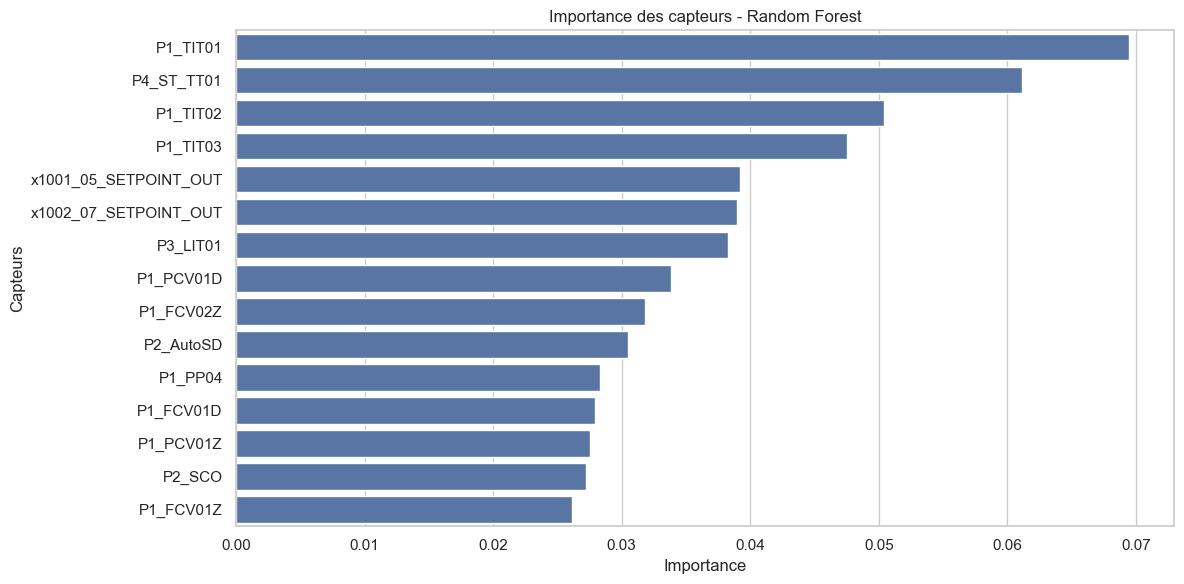

In [27]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    balanced_accuracy_score
)

# 1. Préparation des données
X = df_test_labeled[sensor_cols].copy()
y = pd.to_numeric(
    df_test_labeled["__label__"]
).astype(int)

# 2. Séparation chronologique : 60 / 20 / 20
n = len(X)

i_train = int(0.60 * n)
i_val = int(0.80 * n)

X_train = X.iloc[:i_train]
X_val = X.iloc[i_train:i_val]
X_eval = X.iloc[i_val:]

y_train = y.iloc[:i_train]
y_val = y.iloc[i_train:i_val]
y_eval = y.iloc[i_val:]

print("Distribution des classes :")
print("Train :\n", y_train.value_counts())
print("Validation :\n", y_val.value_counts())
print("Evaluation :\n", y_eval.value_counts())

# 3. Imputation : ajustée uniquement sur Train
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_val = imputer.transform(X_val)
X_eval = imputer.transform(X_eval)

# 4. Entraînement Random Forest
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced_subsample",
    n_jobs=-1
)

rf.fit(X_train, y_train)

# 5. Choix du seuil sur Validation
val_proba = rf.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, val_proba
)

# F1 pour chaque seuil
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-10)
)

best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print("Seuil sélectionné :", round(best_threshold, 4))
print("F1 validation :", round(f1_scores[best_idx], 4))

# 6. Evaluation finale sur la dernière période
eval_proba = rf.predict_proba(X_eval)[:, 1]

y_pred = (
    eval_proba >= best_threshold
).astype(int)

print("\nRapport de classification :")
print(classification_report(
    y_eval, y_pred,
    target_names=["Normal", "Attack"],
    zero_division=0
))

print("Matrice de confusion :")
print(confusion_matrix(y_eval, y_pred))

print(
    "Balanced Accuracy :",
    round(balanced_accuracy_score(y_eval, y_pred), 4)
)

print(
    "ROC-AUC :",
    round(roc_auc_score(y_eval, eval_proba), 4)
)

print(
    "PR-AUC :",
    round(average_precision_score(y_eval, eval_proba), 4)
)

# 7. Importance des variables
importance = pd.DataFrame({
    "Feature": sensor_cols,
    "Importance": rf.feature_importances_
}).sort_values(
    "Importance", ascending=False
)

display(importance.head(15))

plt.figure(figsize=(12, 6))

sns.barplot(
    data=importance.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Importance des capteurs - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Capteurs")
plt.tight_layout()
plt.show()


Le modèle obtient un ROC-AUC de 0,8137, mais détecte seulement 24,5 % des attaques. Malgré une bonne capacité de discrimination, le rappel et le F1-score restent faibles. Ces résultats montrent les difficultés de détection des attaques dans un contexte de données déséquilibrées.